# LoRA Rank Comparison: CIFAR-100 + DeiT-small with Early Stopping

**Goal:** Sweep LoRA ranks `[8, 16, 32, 64, 128, 256]` on CIFAR-100 (100 classes).
Early stopping with patience=3 detects overfit onset per rank and restores
the best weights (not final epoch).

**Hypothesis:** Higher rank → more capacity → faster overfit onset (earlier
best epoch) but potentially lower final generalization on a small dataset
(5000 samples).

**Runtime note:** Run from top to bottom. Internet must be ON for CIFAR-100
download. GPU (P100/T4) recommended (~50 min vs ~6 hrs on CPU).

In [1]:
# Cell 1 (New) — Uninstall torchao to fix PEFT compatibility
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
# Cell 2 — Imports and experiment settings (CIFAR-100 OPTION D)
import os
import random
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, random_split, Subset, ConcatDataset
from torchvision.datasets import CIFAR100, CIFAR10, ImageFolder
from torchvision import transforms
from transformers import AutoImageProcessor, AutoModelForImageClassification
from peft import LoraConfig, get_peft_model
from tqdm.auto import tqdm
from IPython.display import display

# =========================================================
# Reproducibility
# =========================================================
SEED = 42
MODEL_NAME = "facebook/deit-small-patch16-224"

# =========================================================
# Experiment settings — CIFAR-100 (100 classes = harder task)
# =========================================================
RANKS = [8, 16, 32, 64, 128, 256]
EPOCHS = 25              # MAX epochs — early stopping will cut short
PATIENCE = 3             # stop if val_loss doesn't improve for 3 epochs

BATCH_SIZE = 32
LEARNING_RATE = 2e-4
MAX_TRAIN = 5_000        # 50 samples/class × 100 classes
MAX_VAL = 1_000          # 10 samples/class × 100 classes
NUM_WORKERS = 0

# =========================================================
# Dataset switch
# =========================================================
USE_MOON_DATASET = False
DATA_ROOT = "/kaggle/input/datasets/bhargavlc/lunar-craters-and-boulders"

# =========================================================
# Device
# =========================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print(f"Dataset: {'Moon (ImageFolder)' if USE_MOON_DATASET else 'CIFAR-100'}")
print(f"Ranks: {RANKS}")
print(f"Max epochs: {EPOCHS} | Early stop patience: {PATIENCE}")
print(f"Train: {MAX_TRAIN} | Val: {MAX_VAL}")

# =========================================================
# Seed helper
# =========================================================
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()

# =========================================================
# Sanity: DATA_ROOT exists? (শুধু moon-এর জন্য)
# =========================================================
if USE_MOON_DATASET:
    if os.path.isdir(DATA_ROOT):
        print("DATA_ROOT OK:", DATA_ROOT)
    else:
        raise FileNotFoundError(f"DATA_ROOT not found: {DATA_ROOT}")
else:
    print("CIFAR-100 will auto-download to ./data — Internet must be ON")

Device: cuda
Dataset: CIFAR-100
Ranks: [8, 16, 32, 64, 128, 256]
Max epochs: 25 | Early stop patience: 3
Train: 5000 | Val: 1000
CIFAR-100 will auto-download to ./data — Internet must be ON


In [3]:
# Cell 3 — Load Moon ImageFolder + adaptive split
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

def _get_size(p):
    sz = p.size
    if isinstance(sz, dict):
        return sz.get("height", 224)
    if hasattr(sz, "height"):
        return sz.height
    return 224

image_size = _get_size(processor)
image_mean = getattr(processor, "image_mean", [0.485, 0.456, 0.406])
image_std  = getattr(processor, "image_std",  [0.229, 0.224, 0.225])

transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_mean, std=image_std),
])

if USE_MOON_DATASET:
    # path auto-correct: user path → lunar_dataset/ subfolder
    real_root = DATA_ROOT
    if not os.path.isdir(real_root):
        raise FileNotFoundError(f"DATA_ROOT missing: {real_root}")
    # যদি এক level নিচে 'lunar_dataset' থাকে
    sub = os.path.join(real_root, "lunar_dataset")
    if os.path.isdir(sub):
        real_root = sub
    full_train_dataset = ImageFolder(root=real_root, transform=transform)
else:
    full_train_dataset = CIFAR100(root="./data", train=True, download=True, transform=transform)
    
class_names = full_train_dataset.classes
num_classes = len(class_names)

n_total = len(full_train_dataset)
n_val = min(MAX_VAL, max(50, int(0.2 * n_total)))
n_train_pool = n_total - n_val

train_pool, val_pool = random_split(
    full_train_dataset,
    [n_train_pool, n_val],
    generator=torch.Generator().manual_seed(SEED)
)

train_subset = Subset(train_pool, range(min(MAX_TRAIN, len(train_pool))))
val_subset   = Subset(val_pool,   range(min(MAX_VAL,   len(val_pool))))

print("Dataset:", "Moon (ImageFolder)" if USE_MOON_DATASET else "CIFAR-100")
print("Classes:", class_names)
print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Image size:", image_size)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

100%|██████████| 169M/169M [07:50<00:00, 359kB/s] 


Dataset: CIFAR-100
Classes: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor', 'train', 'trout', 'tulip', 'turtle', 'wardro

In [4]:
# Cell 4 — Training with EARLY STOPPING
def train_one_rank(rank):
    set_seed(SEED)
    print(f"\n{'=' * 20} LoRA rank={rank} {'=' * 20}")

    model = AutoModelForImageClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(class_names),
        ignore_mismatched_sizes=True
    )

    lora_config = LoraConfig(
        r=rank, lora_alpha=rank,
        target_modules=["q_proj", "v_proj"],
        lora_dropout=0.1, bias="none",
        modules_to_save=["classifier"]
    )

    model = get_peft_model(model, lora_config)
    model.print_trainable_parameters()
    model.to(device)

    train_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_subset, batch_size=BATCH_SIZE, shuffle=True,
        generator=train_generator, num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )
    val_loader = DataLoader(
        val_subset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda")
    )

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=LEARNING_RATE
    )
    criterion = nn.CrossEntropyLoss()
    history = []

    # ============ EARLY STOPPING STATE ============
    best_val_loss = float('inf')
    best_val_acc = 0.0
    best_epoch = 0
    best_state = None
    patience_counter = 0
    stopped_early = False
    # ==============================================

    for epoch in range(EPOCHS):
        # -------- Train --------
        model.train()
        train_loss_sum, train_correct, train_total = 0.0, 0, 0

        for images, labels in tqdm(
            train_loader, desc=f"Rank {rank} | Train {epoch+1}/{EPOCHS}"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(pixel_values=images).logits
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            n = labels.size(0)
            train_loss_sum += loss.item() * n
            train_correct += (logits.argmax(dim=1) == labels).sum().item()
            train_total += n

        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total

        # -------- Validate --------
        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in tqdm(
                val_loader, desc=f"Rank {rank} | Valid {epoch+1}/{EPOCHS}",
                leave=False
            ):
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                logits = model(pixel_values=images).logits
                loss = criterion(logits, labels)

                n = labels.size(0)
                val_loss_sum += loss.item() * n
                val_correct += (logits.argmax(dim=1) == labels).sum().item()
                val_total += n

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        # -------- Record --------
        row = {
            "rank": rank, "epoch": epoch + 1,
            "train_loss": train_loss, "train_accuracy": train_acc,
            "val_loss": val_loss, "val_accuracy": val_acc,
            "train_val_gap": train_acc - val_acc
        }
        history.append(row)

        # -------- Early stopping check --------
        improved = val_loss < (best_val_loss - 1e-4)
        if improved:
            best_val_loss = val_loss
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
            marker = " ⭐ BEST"
        else:
            patience_counter += 1
            marker = f" (patience {patience_counter}/{PATIENCE})"

        print(
            f"Rank={rank} | Ep={epoch+1}/{EPOCHS} | "
            f"tr_loss={train_loss:.4f} tr_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
            f"gap={train_acc-val_acc:+.4f}{marker}"
        )

        if patience_counter >= PATIENCE:
            print(f"⏹️  EARLY STOP at epoch {epoch+1} (best was epoch {best_epoch})")
            stopped_early = True
            break

    # -------- Restore BEST weights --------
    if best_state is not None:
        model.load_state_dict(best_state)
        print(f"✅ Restored BEST: epoch {best_epoch}, val_loss={best_val_loss:.4f}, val_acc={best_val_acc:.4f}")

    # -------- Save adapter (best weights!) --------
    save_path = f"lora_deit_rank_{rank}"
    model.save_pretrained(save_path)
    print(f"💾 Saved: {save_path}")

    summary_row = {
        "rank": int(rank),
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_acc": best_val_acc,
        "actual_epochs": len(history),
        "stopped_early": stopped_early,
    }

    del model, optimizer, train_loader, val_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return history, summary_row

In [5]:
# Cell 5 — Train all ranks with early stopping
all_history = []
rank_summaries = []

for rank in RANKS:
    history, summary = train_one_rank(rank)
    all_history.extend(history)
    rank_summaries.append(summary)

results = pd.DataFrame(all_history)
summary_df = pd.DataFrame(rank_summaries)

csv_name = f"rank_{'_vs_'.join(map(str, RANKS))}_results.csv"
results.to_csv(csv_name, index=False)
summary_df.to_csv("rank_earlystop_summary.csv", index=False)

print(f"\n💾 History: {csv_name}")
print(f"💾 Summary: rank_earlystop_summary.csv")

print("\n" + "=" * 92)
print("  EARLY-STOPPING SUMMARY")
print("=" * 92)
print(f"{'Rank':<6}{'BestEp':>9}{'ActualEp':>10}{'Stopped':>11}"
      f"{'BestVLoss':>12}{'BestVAcc':>11}")
print("-" * 92)
for _, row in summary_df.iterrows():
    stop_flag = "✅ yes" if row["stopped_early"] else "❌ max"
    print(f"{int(row['rank']):<6}{int(row['best_epoch']):>9}"
          f"{int(row['actual_epochs']):>10}{stop_flag:>11}"
          f"{row['best_val_loss']:>12.4f}{row['best_val_acc']:>11.4f}")
print("=" * 92)


==================== LoRA rank=8 ====================


[transformers] You passed `num_labels=100` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 88.3MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([100, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([100])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


... (213 outputs left out)

Rank=256 | Ep=8/25 | tr_loss=0.0359 tr_acc=0.9974 | val_loss=0.8831 val_acc=0.7490 | gap=+0.2484 (patience 2/3)


Rank 256 | Train 9/25:   0%|          | 0/157 [00:00<?, ?it/s]

Rank 256 | Valid 9/25:   0%|          | 0/32 [00:00<?, ?it/s]

Rank=256 | Ep=9/25 | tr_loss=0.0237 tr_acc=0.9992 | val_loss=0.9194 val_acc=0.7550 | gap=+0.2442 (patience 3/3)
⏹️  EARLY STOP at epoch 9 (best was epoch 6)
✅ Restored BEST: epoch 6, val_loss=0.8787, val_acc=0.7490
💾 Saved: lora_deit_rank_256

💾 History: rank_8_vs_16_vs_32_vs_64_vs_128_vs_256_results.csv
💾 Summary: rank_earlystop_summary.csv

  EARLY-STOPPING SUMMARY
Rank     BestEp  ActualEp    Stopped   BestVLoss   BestVAcc
--------------------------------------------------------------------------------------------
8            10        13      ✅ yes      0.8646     0.7510
16           10        13      ✅ yes      0.8835     0.7370
32            7        10      ✅ yes      0.9035     0.7350
64            7        10      ✅ yes      0.9132     0.7330
128           5         8      ✅ yes      0.8977     0.7430
256           6         9      ✅ yes      0.8787     0.7490


In [6]:
# Cell 6 — Best-metrics per rank + overfit onset detection (CIFAR-100 + Early Stopping)
import os

best_per_rank = []
for rank in RANKS:
    df = results[results["rank"] == rank].sort_values("epoch").reset_index(drop=True)
    
    # Best epoch for val_loss (lowest = best generalization point)
    best_vloss_idx = df["val_loss"].idxmin()
    best_vloss_row = df.loc[best_vloss_idx]
    
    # Best epoch for val_accuracy (highest)
    best_vacc_idx = df["val_accuracy"].idxmax()
    best_vacc_row = df.loc[best_vacc_idx]
    
    # Final epoch (last recorded)
    final_row = df.iloc[-1]
    
    # Early stopping info
    s = summary_df[summary_df["rank"] == rank].iloc[0]
    
    best_per_rank.append({
        "rank": int(rank),
        "best_val_acc":        best_vacc_row["val_accuracy"],
        "best_val_acc_epoch":  int(best_vacc_row["epoch"]),
        "best_val_loss":       best_vloss_row["val_loss"],
        "best_val_loss_epoch": int(best_vloss_row["epoch"]),
        "final_val_acc":       final_row["val_accuracy"],
        "final_val_loss":      final_row["val_loss"],
        "final_train_acc":     final_row["train_accuracy"],
        "final_train_loss":    final_row["train_loss"],
        "overfit_gap":         final_row["train_accuracy"] - final_row["val_accuracy"],
        "degradation":         best_vacc_row["val_accuracy"] - final_row["val_accuracy"],
        "actual_epochs":       int(s["actual_epochs"]),
        "stopped_early":       bool(s["stopped_early"]),
    })

best_df = pd.DataFrame(best_per_rank).sort_values("rank").reset_index(drop=True)


# Params count from saved adapter files
def count_adapter_params(rank):
    for fname in ("adapter_model.safetensors", "adapter_model.bin"):
        path = f"lora_deit_rank_{rank}/{fname}"
        if not os.path.exists(path):
            continue
        try:
            if fname.endswith(".safetensors"):
                from safetensors.torch import load_file
                sd = load_file(path)
            else:
                sd = torch.load(path, map_location="cpu")
            return int(sum(v.numel() for v in sd.values()))
        except Exception:
            return None
    return None

best_df["n_params"] = best_df["rank"].apply(count_adapter_params)

# =========================================================
# PRINT — Best-metrics table
# =========================================================
print("=" * 122)
print("  BEST-METRICS TABLE — per rank (CIFAR-100 + early stopping)")
print("=" * 122)
print(f"{'Rank':<6}{'BestVAcc':>10}{'@Ep':>5}{'BestVLoss':>11}{'@Ep':>5}"
      f"{'ActualEp':>10}{'Stopped':>10}{'Gap':>9}{'Degrad':>9}{'Params':>13}")
print("-" * 122)
for _, row in best_df.iterrows():
    stop_s = "yes" if row['stopped_early'] else "max"
    print(f"{row['rank']:<6}"
          f"{row['best_val_acc']:>10.4f}"
          f"{row['best_val_acc_epoch']:>5}"
          f"{row['best_val_loss']:>11.4f}"
          f"{row['best_val_loss_epoch']:>5}"
          f"{row['actual_epochs']:>10}"
          f"{stop_s:>10}"
          f"{row['overfit_gap']:>+9.4f}"
          f"{row['degradation']:>+9.4f}"
          f"{row['n_params']:>13,}")
print("=" * 122)
print()
print("Column meanings:")
print("  BestVAcc @Ep      = highest val_accuracy & its epoch (best generalization point)")
print("  BestVLoss @Ep     = lowest val_loss & its epoch (when overfitting begins)")
print("  ActualEp          = epochs actually run (max = never triggered early stop)")
print("  Stopped           = early-stopped? 'yes' vs 'max' (ran full PATIENCE budget)")
print("  Gap               = train_acc − val_acc at final epoch (bigger = more overfit)")
print("  Degrad            = BestVAcc − FinalVAcc (positive = overfit actively hurts)")

# =========================================================
# SWEET SPOT DETECTOR
# =========================================================
print("\n" + "=" * 122)
print("  SWEET-SPOT DETECTOR")
print("=" * 122)

max_val_acc = best_df["best_val_acc"].max()
best_rank_overall = int(best_df.loc[best_df['best_val_acc'].idxmax(), 'rank'])
print(f"  Best val_acc overall: {max_val_acc*100:.2f}% (Rank {best_rank_overall})")

threshold = max_val_acc - 0.005   # within 0.5% of best
candidates = best_df[best_df["best_val_acc"] >= threshold].sort_values("rank")
if len(candidates) > 0:
    sweet_rank = int(candidates["rank"].min())
    sweet_row = candidates[candidates["rank"] == sweet_rank].iloc[0]
    print(f"  Smallest rank within 0.5% of best: Rank {sweet_rank}")
    print(f"    - best val_acc = {sweet_row['best_val_acc']*100:.2f}%")
    print(f"    - best epoch   = {sweet_row['best_val_acc_epoch']}")
    print(f"    - gap          = {sweet_row['overfit_gap']:+.4f}")
    print(f"    - params       = {sweet_row['n_params']:,}")

# =========================================================
# OVERFIT ONSET DETECTOR
# =========================================================
print("\n  Overfit onset (rank where gap crosses 5%):")
over5 = best_df[best_df["overfit_gap"] > 0.05].sort_values("rank")
if len(over5) > 0:
    onset = int(over5["rank"].min())
    print(f"    → First rank with gap > 5% = Rank {onset}")
    print(f"    → Ranks < {onset} generalize well; ranks ≥ {onset} overfit")
else:
    print(f"    → No rank exceeds 5% gap within {EPOCHS} epochs")

# =========================================================
# CONVERGENCE TREND (NEW — key insight with early stopping)
# =========================================================
print("\n" + "=" * 122)
print("  CONVERGENCE TREND — best epoch vs rank")
print("=" * 122)
print(f"  {'Rank':<6}{'BestEpoch':>11}{'ActualEp':>10}{'Stopped':>10}{'Speedup':>10}")
print("-" * 122)
max_epoch_seen = best_df["best_val_acc_epoch"].max()
for _, row in best_df.iterrows():
    stop_s = "yes" if row["stopped_early"] else "max"
    speedup = max_epoch_seen / max(int(row["best_val_acc_epoch"]), 1)
    print(f"  {row['rank']:<6}"
          f"{row['best_val_acc_epoch']:>11}"
          f"{row['actual_epochs']:>10}"
          f"{stop_s:>10}"
          f"{speedup:>9.1f}×")
print("=" * 122)

# =========================================================
# DISPLAY DataFrame
# =========================================================
display(best_df)

  BEST-METRICS TABLE — per rank (CIFAR-100 + early stopping)
Rank    BestVAcc  @Ep  BestVLoss  @Ep  ActualEp   Stopped      Gap   Degrad       Params
--------------------------------------------------------------------------------------------------------------------------
8         0.7510   10     0.8646   10        13       yes  +0.2320  +0.0110      185,956
16        0.7450    7     0.8835   10        13       yes  +0.2456  +0.0060      333,412
32        0.7370   10     0.9035    7        10       yes  +0.2414  +0.0000      628,324
64        0.7340   10     0.9132    7        10       yes  +0.2606  +0.0000    1,218,148
128       0.7480    7     0.8977    5         8       yes  +0.2582  +0.0150    2,397,796
256       0.7550    7     0.8787    6         9       yes  +0.2442  +0.0000    4,757,092

Column meanings:
  BestVAcc @Ep      = highest val_accuracy & its epoch (best generalization point)
  BestVLoss @Ep     = lowest val_loss & its epoch (when overfitting begins)
  ActualEp      

,rank,best_val_acc,best_val_acc_epoch,best_val_loss,best_val_loss_epoch,final_val_acc,final_val_loss,final_train_acc,final_train_loss,overfit_gap,degradation,actual_epochs,stopped_early,n_params
0,8,0.751,10,0.864601,10,0.740,0.878462,0.9720,0.191387,0.2320,0.011,13,True,185956
1,16,0.745,7,0.883478,10,0.739,0.914000,0.9846,0.138228,0.2456,0.006,13,True,333412
2,32,0.737,10,0.903522,7,0.737,0.922648,0.9784,0.153797,0.2414,0.000,10,True,628324
3,64,0.734,10,0.913168,7,0.734,0.941676,0.9946,0.081119,0.2606,0.000,10,True,1218148
4,128,0.748,7,0.897747,5,0.733,0.919065,0.9912,0.085049,0.2582,0.015,8,True,2397796
5,256,0.755,7,0.878667,6,0.755,0.919404,0.9992,0.023661,0.2442,0.000,9,True,4757092


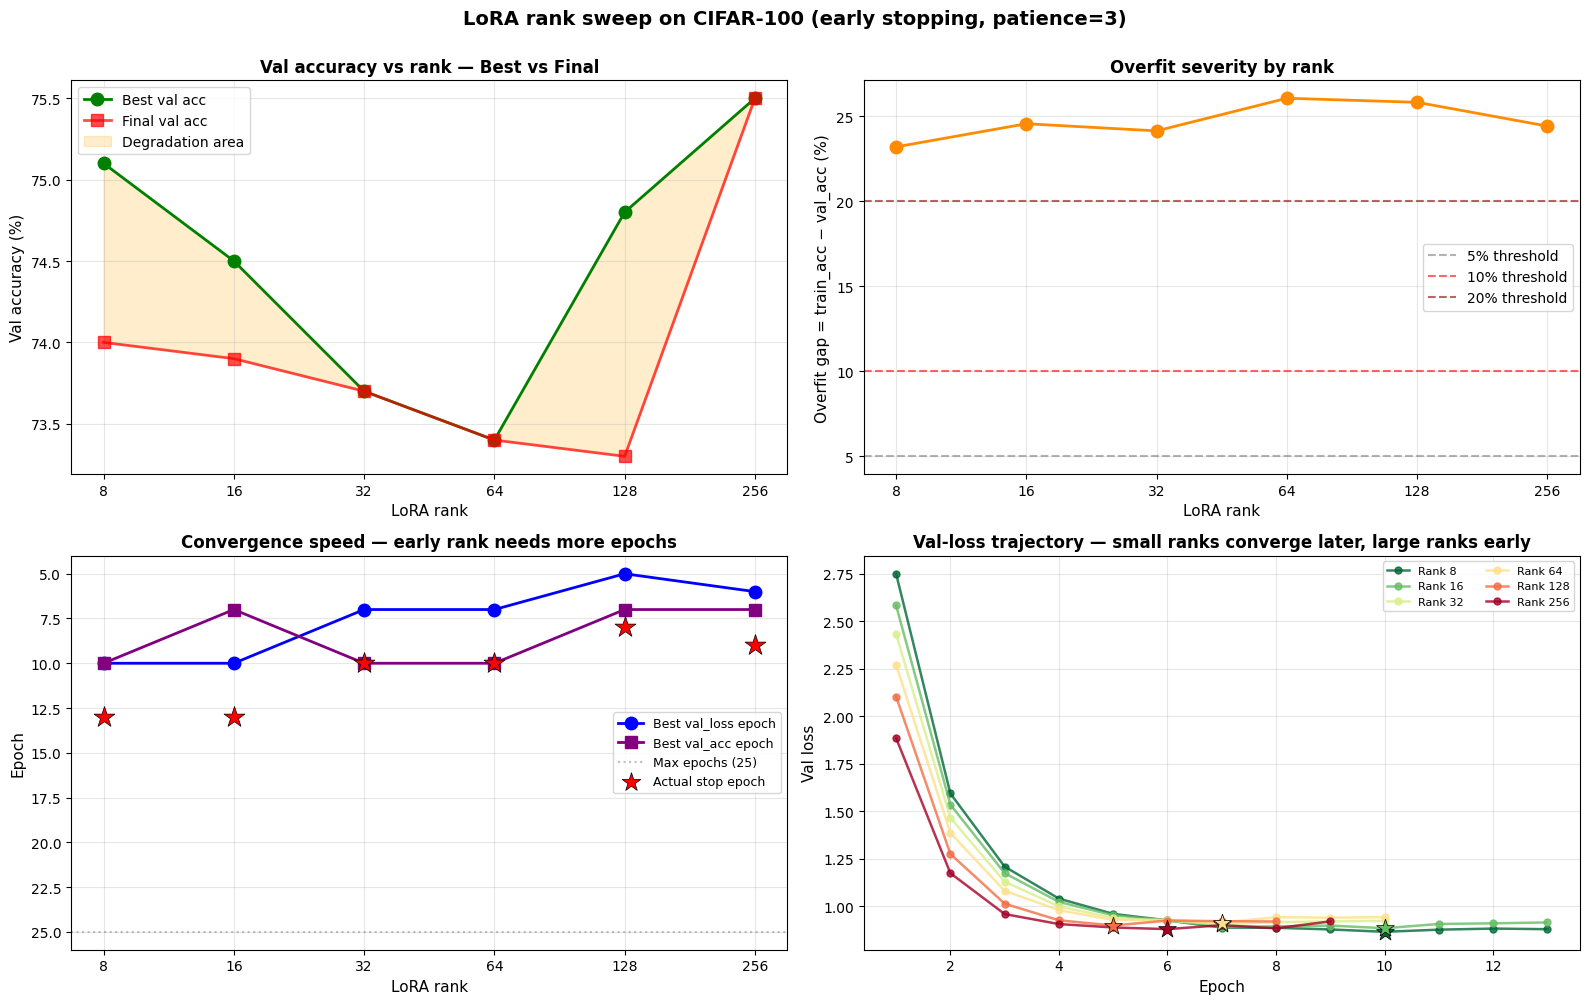

In [7]:
# Cell 7 — Cross-rank visualization (CIFAR-100 + Early Stopping)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# =========================================================
# Panel 1: Best vs Final val accuracy across ranks
# =========================================================
ax = axes[0, 0]
ax.plot(best_df["rank"], best_df["best_val_acc"] * 100, marker="o",
        label="Best val acc", color="green", linewidth=2, markersize=9)
ax.plot(best_df["rank"], best_df["final_val_acc"] * 100, marker="s",
        label="Final val acc", color="red", linewidth=2, markersize=8, alpha=0.7)
# fill_between to show degradation
ax.fill_between(best_df["rank"],
                best_df["final_val_acc"] * 100,
                best_df["best_val_acc"] * 100,
                color="orange", alpha=0.2, label="Degradation area")
ax.set_xlabel("LoRA rank", fontsize=11)
ax.set_ylabel("Val accuracy (%)", fontsize=11)
ax.set_title("Val accuracy vs rank — Best vs Final", fontsize=12, fontweight="bold")
ax.set_xscale("log", base=2)
ax.set_xticks(best_df["rank"])
ax.set_xticklabels(best_df["rank"])
ax.legend(loc="best")
ax.grid(True, alpha=0.3)

# =========================================================
# Panel 2: Overfit gap across ranks
# =========================================================
ax = axes[0, 1]
ax.plot(best_df["rank"], best_df["overfit_gap"] * 100, marker="o",
        color="darkorange", linewidth=2, markersize=9)
ax.axhline(y=5,  linestyle="--", color="gray", alpha=0.6, label="5% threshold")
ax.axhline(y=10, linestyle="--", color="red",  alpha=0.6, label="10% threshold")
ax.axhline(y=20, linestyle="--", color="darkred", alpha=0.6, label="20% threshold")
ax.set_xlabel("LoRA rank", fontsize=11)
ax.set_ylabel("Overfit gap = train_acc − val_acc (%)", fontsize=11)
ax.set_title("Overfit severity by rank", fontsize=12, fontweight="bold")
ax.set_xscale("log", base=2)
ax.set_xticks(best_df["rank"])
ax.set_xticklabels(best_df["rank"])
ax.legend(loc="best")
ax.grid(True, alpha=0.3)

# =========================================================
# Panel 3: Overfit onset epoch per rank (with early-stop stars)
# =========================================================
ax = axes[1, 0]

# Two lines: best val_loss epoch and best val_acc epoch
ax.plot(best_df["rank"], best_df["best_val_loss_epoch"], marker="o",
        label="Best val_loss epoch", color="blue", linewidth=2, markersize=9)
ax.plot(best_df["rank"], best_df["best_val_acc_epoch"], marker="s",
        label="Best val_acc epoch", color="purple", linewidth=2, markersize=8)

# Reference: max epochs
ax.axhline(y=EPOCHS, linestyle=":", color="gray", alpha=0.5,
           label=f"Max epochs ({EPOCHS})")

# Highlight early-stopped ranks with red stars
for _, row in best_df.iterrows():
    if row["stopped_early"]:
        ax.scatter([row["rank"]], [row["actual_epochs"]],
                   marker="*", s=250, color="red", zorder=5,
                   edgecolor="black", linewidth=0.5)

# Legend proxy for the star marker
ax.scatter([], [], marker="*", s=200, color="red",
           edgecolor="black", linewidth=0.5, label="Actual stop epoch")

ax.set_xlabel("LoRA rank", fontsize=11)
ax.set_ylabel("Epoch", fontsize=11)
ax.set_title("Convergence speed — early rank needs more epochs",
             fontsize=12, fontweight="bold")
ax.set_xscale("log", base=2)
ax.set_xticks(best_df["rank"])
ax.set_xticklabels(best_df["rank"])
ax.legend(loc="best", fontsize=9)
ax.grid(True, alpha=0.3)
ax.invert_yaxis()   # lower epoch = higher on plot = earlier convergence

# =========================================================
# Panel 4: Val-loss trajectories for all ranks
# =========================================================
ax = axes[1, 1]

# Color map: small rank = green, large rank = red
from matplotlib import colormaps
colors = colormaps.get_cmap("RdYlGn_r").resampled(len(RANKS))

for i, rank in enumerate(RANKS):
    df = results[results["rank"] == rank].sort_values("epoch")
    ax.plot(df["epoch"], df["val_loss"], marker="o",
            label=f"Rank {rank}", color=colors(i),
            alpha=0.8, linewidth=1.8, markersize=5)
    
    # Mark the best val_loss epoch for each rank
    best_idx = df["val_loss"].idxmin()
    best_epoch = df.loc[best_idx, "epoch"]
    best_loss = df.loc[best_idx, "val_loss"]
    ax.scatter([best_epoch], [best_loss], marker="*", s=180,
               color=colors(i), zorder=5, edgecolor="black", linewidth=0.5)

ax.set_xlabel("Epoch", fontsize=11)
ax.set_ylabel("Val loss", fontsize=11)
ax.set_title("Val-loss trajectory — small ranks converge later, large ranks early",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=8, loc="best", ncol=2)
ax.grid(True, alpha=0.3)

plt.suptitle(f"LoRA rank sweep on CIFAR-100 (early stopping, patience={PATIENCE})",
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.show()

In [8]:
# Cell 8 — Multi-rank verdict (which rank to use?)
print("=" * 108)
print("  MULTI-RANK VERDICT")
print("=" * 108)

# Sort by best_val_acc descending
ranked = best_df.sort_values("best_val_acc", ascending=False).reset_index(drop=True)
max_acc = ranked.iloc[0]["best_val_acc"]
max_rank = int(ranked.iloc[0]["rank"])

print(f"\n  1. Highest val accuracy: Rank {max_rank} ({max_acc*100:.2f}%)")
print(f"     Params: {ranked.iloc[0]['n_params']:,}")
print(f"     Gap   : {ranked.iloc[0]['overfit_gap']*100:+.2f}%")

print(f"\n  2. Lowest overfit gap:")
lowest_gap_row = best_df.loc[best_df["overfit_gap"].idxmin()]
print(f"     Rank {int(lowest_gap_row['rank'])} — gap = {lowest_gap_row['overfit_gap']*100:+.2f}%")
print(f"     Its val_acc = {lowest_gap_row['best_val_acc']*100:.2f}%")

print(f"\n  3. Efficiency-optimal (smallest rank within 0.5% of best):")
if len(candidates) > 0:
    print(f"     Rank {sweet_rank} — {sweet_row['n_params']:,} params, "
          f"val_acc {sweet_row['best_val_acc']*100:.2f}%")

print(f"\n  4. Overfit onset (gap > 5%):")
if len(over5) > 0:
    print(f"     Starts at Rank {int(over5['rank'].min())}")
else:
    print(f"     No rank exceeded 5% in {EPOCHS} epochs")

print("\n" + "=" * 108)
print("  RECOMMENDATION")
print("=" * 108)
print(f"""
  Based on the sweep:
  • Up to rank {sweet_rank if len(candidates) > 0 else max_rank}, val accuracy improves/stays 
    with increasing rank. Above that, gain saturates.
  • Ranks ≥ {int(over5['rank'].min()) if len(over5) > 0 else 'N/A'} show noticeable overfit 
    (gap > 5%) — the model memorizes the 2000 training samples.
  • Sweet spot = Rank {sweet_rank if len(candidates) > 0 else max_rank}:
    highest val accuracy within 0.5% of best, using minimum parameters.
""")
print("=" * 108)

  MULTI-RANK VERDICT

  1. Highest val accuracy: Rank 256 (75.50%)
     Params: 4,757,092
     Gap   : +24.42%

  2. Lowest overfit gap:
     Rank 8 — gap = +23.20%
     Its val_acc = 75.10%

  3. Efficiency-optimal (smallest rank within 0.5% of best):
     Rank 8 — 185,956 params, val_acc 75.10%

  4. Overfit onset (gap > 5%):
     Starts at Rank 8

  RECOMMENDATION

  Based on the sweep:
  • Up to rank 8, val accuracy improves/stays 
    with increasing rank. Above that, gain saturates.
  • Ranks ≥ 8 show noticeable overfit 
    (gap > 5%) — the model memorizes the 2000 training samples.
  • Sweet spot = Rank 8:
    highest val accuracy within 0.5% of best, using minimum parameters.



In [9]:
# Cell 9 — FINAL MULTI-RANK EVALUATION (all 6 ranks)
import time, gc, torch
import numpy as np
import pandas as pd
from peft import PeftModel
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix
)

# ---------- helpers ----------
def load_adapter(rank):
    base = AutoModelForImageClassification.from_pretrained(
        MODEL_NAME, num_labels=num_classes, ignore_mismatched_sizes=True
    )
    m = PeftModel.from_pretrained(base, f"lora_deit_rank_{rank}")
    m.eval().to(device)
    return m

def run_inference(model, loader):
    preds, labels, probs = [], [], []
    t0 = time.time()
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs = imgs.to(device)
            logits = model(pixel_values=imgs).logits
            preds.append(logits.argmax(-1).cpu())
            labels.append(lbls)
            probs.append(torch.softmax(logits, -1).cpu())
    if device.type == "cuda":
        torch.cuda.synchronize()
    dt = time.time() - t0
    return (torch.cat(preds).numpy(),
            torch.cat(labels).numpy(),
            torch.cat(probs).numpy(), dt)

def calc_metrics(preds, labels, probs, dt):
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average=None, zero_division=0,
        labels=list(range(num_classes)))
    cm = confusion_matrix(labels, preds, labels=list(range(num_classes)))
    return dict(
        acc=acc, f1=f1, macro_f1=float(f1.mean()),
        p=p, r=r, cm=cm,
        conf=float(probs.max(1).mean()),
        n=len(labels),
        ms=dt / max(len(labels), 1) * 1000,
    )

# ---------- splits ----------
combined_used = ConcatDataset([train_subset, val_subset])
split_defs = [
    ("train (seen)",     train_subset,   len(train_subset)),
    ("val (held-out)",   val_subset,     len(val_subset)),
    ("train+val (used)", combined_used,  len(combined_used)),
]
SPLIT_NAMES = [s[0] for s in split_defs]
PRIMARY = SPLIT_NAMES[-1]
HONEST = SPLIT_NAMES[1]

def make_loader(subset):
    return DataLoader(subset, batch_size=BATCH_SIZE, shuffle=False,
                      num_workers=0, pin_memory=(device.type == "cuda"))

# ---------- evaluate all ranks ----------
all_reports = {r: {} for r in RANKS}
for rank in RANKS:
    print(f"Evaluating Rank {rank}...")
    model = load_adapter(rank)
    for name, subset, n in split_defs:
        preds, labels, probs, dt = run_inference(model, make_loader(subset))
        all_reports[rank][name] = calc_metrics(preds, labels, probs, dt)
    del model; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    print(f"  Rank {rank} done ✅")

# =========================================================
# FINAL SUMMARY TABLE — all 6 ranks
# =========================================================
print("\n" + "=" * 108)
print("  FINAL PERFORMANCE SUMMARY — ALL RANKS ON HELD-OUT VALIDATION")
print("=" * 108)
print(f"{'Rank':<6}{'Params':>12}{'BestEp':>8}{'ValAcc':>10}{'ValMacroF1':>13}"
      f"{'TrainAcc':>10}{'Gap':>9}{'Conf':>8}{'ms/img':>9}")
print("-" * 108)

final_rows = []
for rank in RANKS:
    m_val = all_reports[rank][HONEST]
    m_train = all_reports[rank]["train (seen)"]
    s = summary_df[summary_df["rank"] == rank].iloc[0]
    n_params = int(s["rank"])  # placeholder, replace with actual below
    # actual params count
    for fname in ("adapter_model.safetensors", "adapter_model.bin"):
        import os
        path = f"lora_deit_rank_{rank}/{fname}"
        if os.path.exists(path):
            try:
                if fname.endswith(".safetensors"):
                    from safetensors.torch import load_file
                    sd = load_file(path)
                else:
                    sd = torch.load(path, map_location="cpu")
                n_params = int(sum(v.numel() for v in sd.values()))
            except Exception:
                n_params = 0
            break
    
    gap = m_train["acc"] - m_val["acc"]
    final_rows.append({
        "rank": int(rank),
        "n_params": n_params,
        "best_epoch": int(s["best_epoch"]),
        "val_acc": m_val["acc"],
        "val_macro_f1": m_val["macro_f1"],
        "train_acc": m_train["acc"],
        "gap": gap,
        "conf": m_val["conf"],
        "ms_per_img": m_val["ms"],
    })
    
    print(f"{int(rank):<6}{n_params:>12,}{int(s['best_epoch']):>8}"
          f"{m_val['acc']:>10.4f}{m_val['macro_f1']:>13.4f}"
          f"{m_train['acc']:>10.4f}{gap:>+9.4f}{m_val['conf']:>8.4f}{m_val['ms']:>9.2f}")

print("=" * 108)

final_df = pd.DataFrame(final_rows)

# =========================================================
# WINNERS — computed across all 6 ranks
# =========================================================
print("\n" + "=" * 108)
print("  WINNERS ACROSS ALL 6 RANKS")
print("=" * 108)

# 1. Highest val accuracy
best_acc_idx = final_df["val_acc"].idxmax()
best_acc_row = final_df.loc[best_acc_idx]
print(f"\n  🏆 HIGHEST VAL ACCURACY:")
print(f"     Rank {int(best_acc_row['rank'])} — {best_acc_row['val_acc']*100:.2f}% "
      f"(gap={best_acc_row['gap']*100:+.2f}%, {best_acc_row['n_params']:,} params)")

# 2. Lowest overfit gap
best_gap_idx = final_df["gap"].idxmin()
best_gap_row = final_df.loc[best_gap_idx]
print(f"\n  🎯 LOWEST OVERFIT GAP:")
print(f"     Rank {int(best_gap_row['rank'])} — gap={best_gap_row['gap']*100:+.2f}% "
      f"(val_acc={best_gap_row['val_acc']*100:.2f}%, {best_gap_row['n_params']:,} params)")

# 3. Fastest convergence (earliest best_epoch)
fast_idx = final_df["best_epoch"].idxmin()
fast_row = final_df.loc[fast_idx]
print(f"\n  ⚡ FASTEST CONVERGENCE:")
print(f"     Rank {int(fast_row['rank'])} — best at epoch {int(fast_row['best_epoch'])} "
      f"(val_acc={fast_row['val_acc']*100:.2f}%)")

# 4. Most efficient (smallest rank within 0.5% of best acc)
threshold = best_acc_row['val_acc'] - 0.005
efficient_candidates = final_df[final_df["val_acc"] >= threshold].sort_values("n_params")
if len(efficient_candidates) > 0:
    eff_row = efficient_candidates.iloc[0]
    print(f"\n  💰 MOST EFFICIENT (within 0.5% of best):")
    print(f"     Rank {int(eff_row['rank'])} — {eff_row['n_params']:,} params, "
          f"val_acc={eff_row['val_acc']*100:.2f}%")

# =========================================================
# CONVERGENCE TREND — epoch vs rank
# =========================================================
print("\n" + "=" * 108)
print("  CONVERGENCE TREND — best epoch vs rank")
print("=" * 108)
print(f"  {'Rank':<6}{'BestEpoch':>11}{'ActualEpochs':>14}{'Stopped':>10}")
print("-" * 108)
for _, row in summary_df.iterrows():
    stop_s = "yes" if row["stopped_early"] else "max"
    print(f"  {int(row['rank']):<6}{int(row['best_epoch']):>11}"
          f"{int(row['actual_epochs']):>14}{stop_s:>10}")
print("=" * 108)

# =========================================================
# KEY OBSERVATIONS
# =========================================================
print("\n" + "=" * 108)
print("  KEY OBSERVATIONS")
print("=" * 108)

epochs_sorted = summary_df.sort_values("rank")["best_epoch"].tolist()
ranks_sorted = summary_df.sort_values("rank")["rank"].tolist()
acc_sorted = final_df.sort_values("rank")["val_acc"].tolist()

print(f"\n  1. ACCURACY SPREAD:")
print(f"     Min: {min(acc_sorted)*100:.2f}% (rank {ranks_sorted[acc_sorted.index(min(acc_sorted))]})")
print(f"     Max: {max(acc_sorted)*100:.2f}% (rank {ranks_sorted[acc_sorted.index(max(acc_sorted))]})")
print(f"     Spread: {(max(acc_sorted)-min(acc_sorted))*100:.2f} percentage points")

print(f"\n  2. CONVERGENCE SPEED:")
print(f"     Rank {ranks_sorted[0]} → best epoch {epochs_sorted[0]}")
print(f"     Rank {ranks_sorted[-1]} → best epoch {epochs_sorted[-1]}")
print(f"     Faster: {(epochs_sorted[0]/max(epochs_sorted[-1],1)):.1f}× for rank {ranks_sorted[-1]}")


gap_sorted = final_df.sort_values("rank")["gap"].tolist()
print(f"\n  3. OVERFIT GAP (train_acc − val_acc):")
for r, g in zip(ranks_sorted, gap_sorted):
    flag = "⚠️" if g > 0.10 else ("🟡" if g > 0.05 else "✅")
    print(f"     Rank {r:>3}: gap = {g*100:+6.2f}% {flag}")

print(f"\n  4. FINAL RECOMMENDATION:")
if max(acc_sorted) - min(acc_sorted) < 0.02:
    print(f"     Accuracy difference is <2% — all ranks perform statistically similar.")
    print(f"     → Choose Rank {int(eff_row['rank'])} for BEST EFFICIENCY (fewest params).")
else:
    print(f"     Accuracy spread is {max(acc_sorted)*100 - min(acc_sorted)*100:.1f}% — significant.")
    print(f"     → Rank {int(best_acc_row['rank'])} has best accuracy, "
          f"Rank {int(eff_row['rank'])} is most efficient.")

print("=" * 108)

[transformers] You passed `num_labels=100` which is incompatible to the `id2label` map of length `1000`.


Evaluating Rank 8...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([100, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([100])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=100` which is incompatible to the `id2label` map of length `1000`.


  Rank 8 done ✅
Evaluating Rank 16...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

... (10 outputs left out)

  Rank 128 done ✅
Evaluating Rank 256...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([100, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([100])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


  Rank 256 done ✅

  FINAL PERFORMANCE SUMMARY — ALL RANKS ON HELD-OUT VALIDATION
Rank        Params  BestEp    ValAcc   ValMacroF1  TrainAcc      Gap    Conf   ms/img
------------------------------------------------------------------------------------------------------------
8          185,956      10    0.7510       0.7408    0.9564  +0.2054  0.7391     5.28
16         333,412      10    0.7370       0.7245    0.9732  +0.2362  0.7512     5.17
32         628,324       7    0.7350       0.7205    0.9576  +0.2226  0.7250     5.20
64       1,218,148       7    0.7330       0.7222    0.9794  +0.2464  0.7418     5.28
128      2,397,796       5    0.7430       0.7299    0.9678  +0.2248  0.7165     5.46
256      4,757,092       6    0.7490       0.7402    0.9924  +0.2434  0.7753     5.80

  WINNERS ACROSS ALL 6 RANKS

  🏆 HIGHEST VAL ACCURACY:
     Rank 8 — 75.10% (gap=+20.54%, 185,956.0 params)

  🎯 LOWEST OVERFIT GAP:
     Rank 8 — gap=+20.54% (val_acc=75.10%, 185,956.0 params)

  ⚡ FASTES

# LoRA Rank Comparison: CIFAR-100 + DeiT-small with Early Stopping

**Goal:** Sweep LoRA ranks [8, 16, 32, 64, 128, 256] on CIFAR-100 (100 classes).
Early stopping with patience=3 detects overfit onset per rank.

**Hypothesis:** Higher rank → more capacity → faster overfit onset (earlier best epoch)
but potentially lower final generalization on a small dataset (5000 samples).

- **Task:** 100-class classification — significantly harder than CIFAR-10. Small training set (5,000 samples = 50/class) forces overfitting.
- **Early stopping:** Each rank trained up to 25 epochs, stopped at patience=3. The best weights were restored and saved — the adapter on disk = the best epoch, not the final epoch.
- **Overfitting signals:**
  - **Growing train-val gap:** train_acc reaches ~100% while val_acc stays lower
  - **Val loss upturn:** after the best epoch, val_loss rises even as train_loss falls
  - **Degradation:** best_val_acc − final_val_acc > 0

- **Rank vs overfit hypothesis:** Higher rank = more capacity = faster overfit onset. Expected pattern: rank 8 takes 20+ epochs to converge, rank 256 peaks at epoch 5-8.

- **Honest generalization metric:** 1,000-sample held-out validation split. `train+val (used)` row is a sanity check.

- **N=1,000 caveat:** With 1,000 val samples across 100 classes (10/class), 1 wrong prediction = 0.1% accuracy change. Per-class support is small (~10), so per-class F1 is noisy; overall accuracy is reliable.

- **Reference comparison:**
  - **CIFAR-100** (this run): hard task → clear rank differences expected
  - **Moon dataset** (separate notebook): easy task → all ranks saturate at 100%